In [2]:
print("Customer Churn Prediction Project Started")

Customer Churn Prediction Project Started


In [5]:
import pandas as pd

print("Pandas version:", pd.__version__)

Pandas version: 3.1.1


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
import joblib
import openpyxl

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [8]:
df = pd.read_csv("../data/customer_churn.csv")


In [9]:
df = pd.read_csv("../data/customer_churn.csv")

In [10]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [11]:
df.shape

(7043, 21)

In [12]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [14]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df["TotalCharges"].value_counts().tail(10)

TotalCharges
2625.25    1
6886.25    1
1495.1     1
743.3      1
1419.4     1
1990.5     1
7362.9     1
346.45     1
306.6      1
6844.5     1
Name: count, dtype: int64

In [17]:
(df["TotalCharges"].str.strip() == "").sum()

np.int64(11)

In [18]:
df[df["TotalCharges"].str.strip() == ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [19]:
df[df["TotalCharges"].str.strip() == ""][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [20]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

In [21]:
df[["TotalCharges"]].info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 1 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   TotalCharges  7032 non-null   float64
dtypes: float64(1)
memory usage: 55.2 KB


In [22]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [23]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [24]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [25]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [26]:
for column in df.select_dtypes(include="str").columns:
    print(f"\n{column}:")
    print(df[column].unique())


customerID:
<StringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7043, dtype: str

gender:
<StringArray>
['Female', 'Male']
Length: 2, dtype: str

Partner:
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

Dependents:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

PhoneService:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

MultipleLines:
<StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str

InternetService:
<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

OnlineSecurity:
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

OnlineBackup:
<StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

DeviceProtection:
<StringArray>
['No', 'Yes', 'No internet 

In [27]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [28]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100
churn_percentage

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

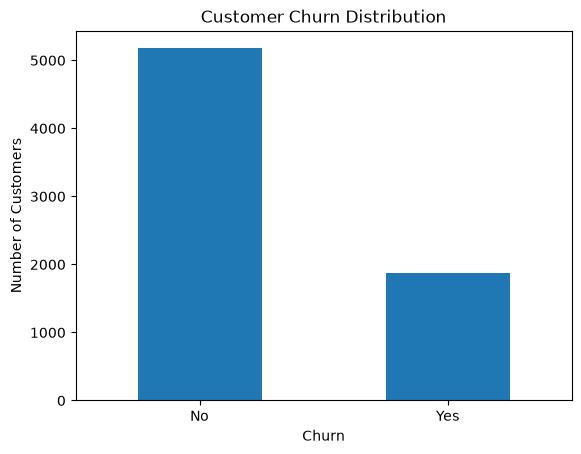

In [29]:
import matplotlib.pyplot as plt

df["Churn"].value_counts().plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

In [30]:
pd.crosstab(df["gender"], df["Churn"])

Churn,No,Yes
gender,,
Female,2549,939
Male,2625,930


In [31]:
gender_churn_rate = pd.crosstab(
    df["gender"],
    df["Churn"],
    normalize="index"
) * 100

gender_churn_rate

Churn,No,Yes
gender,,
Female,73.079128,26.920872
Male,73.839662,26.160338


In [32]:
contract_churn_rate = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn_rate

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [33]:
df["tenure"].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

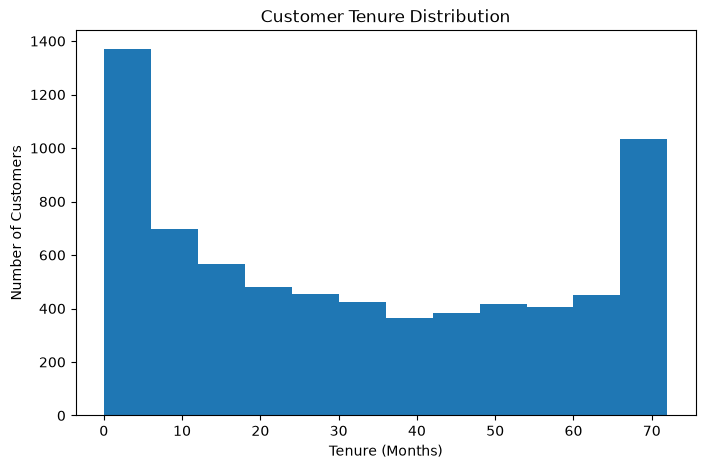

In [34]:
plt.figure(figsize=(8, 5))

plt.hist(df["tenure"], bins=12)

plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

In [35]:
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 36, 48, 72],
    labels=["0-12", "13-24", "25-36", "37-48", "49-72"]
)

tenure_churn_rate = pd.crosstab(
    df["tenure_group"],
    df["Churn"],
    normalize="index"
) * 100

tenure_churn_rate

Churn,No,Yes
tenure_group,,
0-12,52.561757,47.438243
13-24,71.289062,28.710938
25-36,78.365385,21.634615
37-48,80.971129,19.028871
49-72,90.486824,9.513176


In [36]:
df["MonthlyCharges"].describe()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64

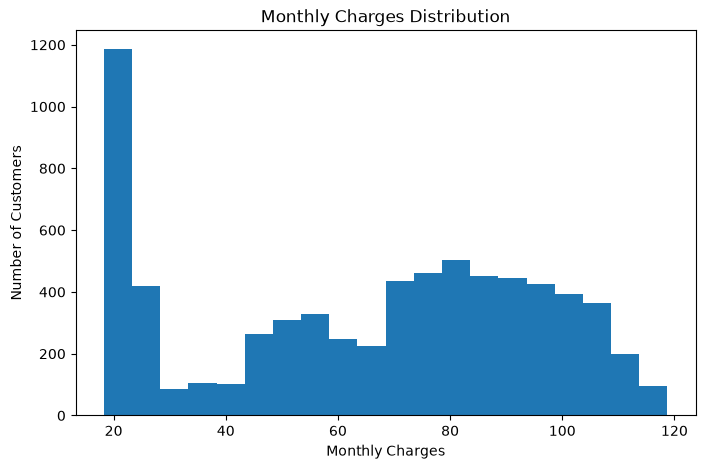

In [37]:
plt.figure(figsize=(8, 5))

plt.hist(df["MonthlyCharges"], bins=20)

plt.title("Monthly Charges Distribution")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.show()

In [38]:
monthly_churn = df.groupby("Churn")["MonthlyCharges"].mean()

monthly_churn

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

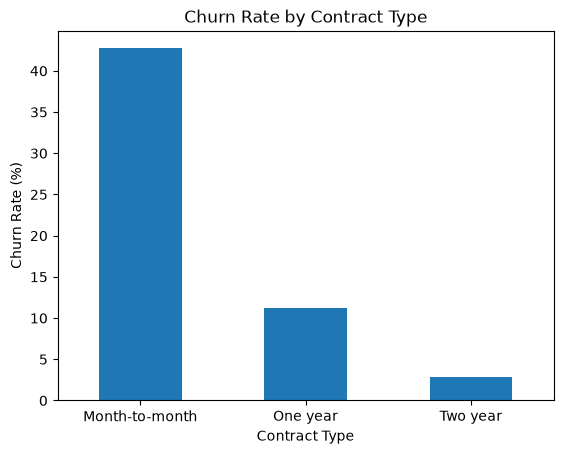

In [39]:
contract_churn_rate["Yes"].plot(kind="bar")

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [40]:
internet_churn_rate = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

internet_churn_rate

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


In [41]:
techsupport_churn_rate = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

techsupport_churn_rate

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


In [42]:
security_churn_rate = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

security_churn_rate

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


In [43]:
payment_churn_rate = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

payment_churn_rate

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


In [44]:
paperless_churn_rate = pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"],
    normalize="index"
) * 100

paperless_churn_rate

Churn,No,Yes
PaperlessBilling,,
No,83.669916,16.330084
Yes,66.434908,33.565092


In [45]:
payment_churn_rate = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

payment_churn_rate

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


In [46]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

In [47]:
df.groupby("Churn")["TotalCharges"].mean()

Churn
No     2549.911442
Yes    1531.796094
Name: TotalCharges, dtype: float64

In [48]:
df.groupby("Churn")["tenure"].mean()


Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

In [49]:
df.select_dtypes(include="number").corr()["Churn"]

KeyError: 'Churn'

In [50]:
df["Churn_encoded"] = df["Churn"].map({"No": 0, "Yes": 1})

df.select_dtypes(include="number").corr()["Churn_encoded"].sort_values(ascending=False)

Churn_encoded     1.000000
MonthlyCharges    0.193356
SeniorCitizen     0.150889
TotalCharges     -0.198324
tenure           -0.352229
Name: Churn_encoded, dtype: float64

In [51]:
from scipy.stats import ttest_ind

In [52]:
churn_yes = df[df["Churn"] == "Yes"]["tenure"]
churn_no = df[df["Churn"] == "No"]["tenure"]

t_stat, p_value = ttest_ind(churn_yes, churn_no)

print("T-statistic:", t_stat)
print("P-value:", p_value)


T-statistic: -31.57955051135377
P-value: 7.999057960590134e-205


In [53]:
churn_yes_charges = df[df["Churn"] == "Yes"]["MonthlyCharges"]
churn_no_charges = df[df["Churn"] == "No"]["MonthlyCharges"]

t_stat, p_value = ttest_ind(
    churn_yes_charges,
    churn_no_charges
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 16.536738015936308
P-value: 2.706645606888385e-60


In [54]:
churn_yes_total = df[df["Churn"] == "Yes"]["TotalCharges"]
churn_no_total = df[df["Churn"] == "No"]["TotalCharges"]

t_stat, p_value = ttest_ind(
    churn_yes_total,
    churn_no_total
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -16.978779727124437
P-value: 2.1272116132402943e-63


In [55]:
from scipy.stats import chi2_contingency

table = pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"]
)

chi2, p_value, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("P-value:", p_value)

Chi-square: 258.27764906707307
P-value: 4.073354668665985e-58


In [56]:
# Remove CustomerID because it is only an identifier
df = df.drop("customerID", axis=1)

# Convert categorical columns into numerical columns
df = pd.get_dummies(df, drop_first=True)

# Display the first 5 rows
df.head()


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn_encoded,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Churn_Yes,tenure_group_13-24,tenure_group_25-36,tenure_group_37-48,tenure_group_49-72
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,True,False,True,False,False,False,False,False,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,True,False,False
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,True,False,False,True,True,False,False,False,False
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,False,False,False,False,True,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,True,False,True,False,True,False,False,False,False


In [57]:
# Separate features (X) and target (y)

X = df.drop("Churn_Yes", axis=1)
y = df["Churn_Yes"]

# Check the shape
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 35)
y shape: (7043,)


In [58]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5634, 35)
X_test shape: (1409, 35)
y_train shape: (5634,)
y_test shape: (1409,)


In [59]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit on training data and transform both training and testing data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (5634, 35)
X_test_scaled shape: (1409, 35)


In [60]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
logistic_model = LogisticRegression(max_iter=1000)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [61]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Make predictions on test data
y_pred = logistic_model.predict(X_test_scaled)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

       False       1.00      1.00      1.00      1035
        True       1.00      1.00      1.00       374

    accuracy                           1.00      1409
   macro avg       1.00      1.00      1.00      1409
weighted avg       1.00      1.00      1.00      1409


Confusion Matrix:
[[1035    0]
 [   0  374]]


In [62]:
print("Target column:", "Churn_Yes")
print("\nColumns containing churn:")
print([col for col in X.columns if "Churn" in col])

Target column: Churn_Yes

Columns containing churn:
['Churn_encoded']


In [63]:
# Remove target-related leakage column
X = df.drop(["Churn_Yes", "Churn_encoded"], axis=1)

# Target
y = df["Churn_Yes"]

print("X shape:", X.shape)
print("Target-related columns in X:")
print([col for col in X.columns if "Churn" in col])

X shape: (7043, 34)
Target-related columns in X:
[]


In [64]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5634, 34)
X_test shape: (1409, 34)
y_train shape: (5634,)
y_test shape: (1409,)


In [65]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (5634, 34)
X_test_scaled shape: (1409, 34)


In [66]:
from sklearn.linear_model import LogisticRegression

# Create the model
logistic_model = LogisticRegression(max_iter=1000)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [67]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predict churn for test data
y_pred = logistic_model.predict(X_test_scaled)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8026969481902059

Classification Report:
              precision    recall  f1-score   support

       False       0.84      0.90      0.87      1035
        True       0.66      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.80      1409


Confusion Matrix:
[[934 101]
 [177 197]]


In [68]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [69]:
# Make predictions
rf_pred = rf_model.predict(X_test)

# Evaluate Random Forest
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest Accuracy: 0.7856635911994322

Classification Report:
              precision    recall  f1-score   support

       False       0.83      0.90      0.86      1035
        True       0.62      0.48      0.54       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.70      1409
weighted avg       0.77      0.79      0.78      1409


Confusion Matrix:
[[927 108]
 [194 180]]


In [70]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [71]:
# Make predictions
xgb_pred = xgb_model.predict(X_test)

# Evaluate XGBoost
xgb_accuracy = accuracy_score(y_test, xgb_pred)

print("XGBoost Accuracy:", xgb_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, xgb_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))

XGBoost Accuracy: 0.7977288857345636

Classification Report:
              precision    recall  f1-score   support

       False       0.84      0.90      0.87      1035
        True       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409


Confusion Matrix:
[[928 107]
 [178 196]]


In [72]:
# Compare all three models

model_comparison = {
    "Logistic Regression": accuracy_score(y_test, y_pred),
    "Random Forest": accuracy_score(y_test, rf_pred),
    "XGBoost": accuracy_score(y_test, xgb_pred)
}

for model, score in model_comparison.items():
    print(f"{model}: {score:.2%}")

Logistic Regression: 80.27%
Random Forest: 78.57%
XGBoost: 79.77%


In [73]:
# Get feature importance from Logistic Regression

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.coef_[0]
})

# Sort by absolute coefficient value
feature_importance["Absolute_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

feature_importance.head(10)

,Feature,Coefficient,Absolute_Coefficient
1,tenure,-1.607935,1.607935
2,MonthlyCharges,-0.838260,0.838260
10,InternetService_Fiber optic,0.784160,0.784160
33,tenure_group_49-72,0.698769,0.698769
25,Contract_Two year,-0.607060,0.607060
24,Contract_One year,-0.297486,0.297486
32,tenure_group_37-48,0.290729,0.290729
23,StreamingMovies_Yes,0.269631,0.269631
21,StreamingTV_Yes,0.265564,0.265564
9,MultipleLines_Yes,0.243680,0.243680


CUSTOMER CHURN PREDICTION - FINAL PIPELINE

Dataset Shape: (7043, 35)
Features: 34
Target: Churn_Yes

Train Shape: (5634, 34)
Test Shape : (1409, 34)

MODEL COMPARISON
                 Model  Accuracy
0  Logistic Regression  0.802697
1              XGBoost  0.797729
2        Random Forest  0.785664


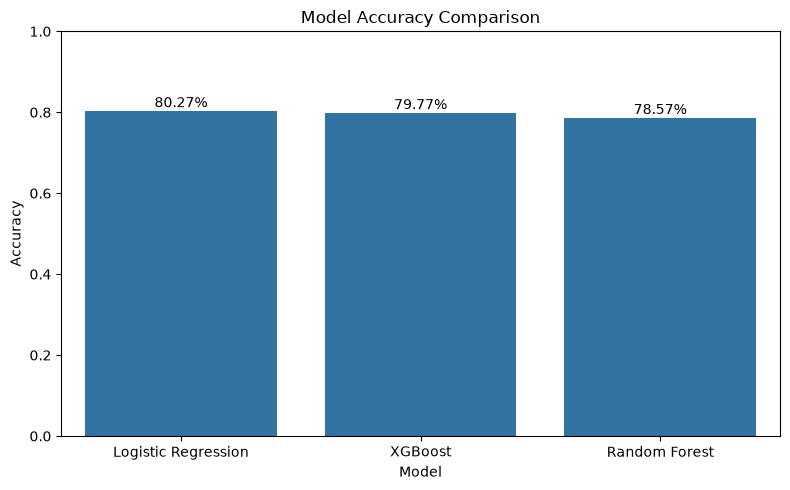


Best Model: Logistic Regression
Best Accuracy: 80.27%

BEST MODEL - CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.66      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.80      1409


Confusion Matrix:
[[934 101]
 [177 197]]


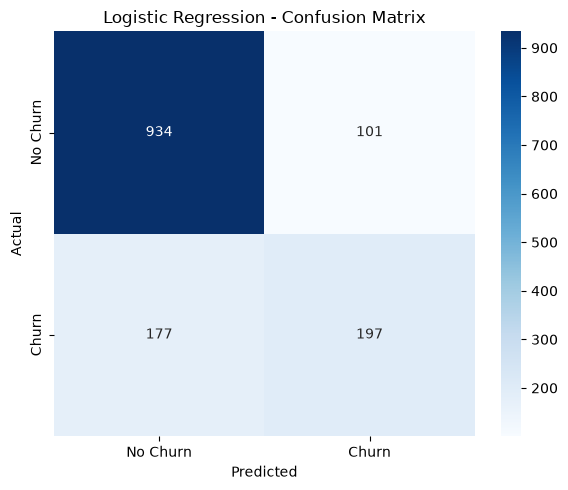


TOP 10 LOGISTIC REGRESSION FEATURES
                        Feature  Coefficient
1                        tenure    -1.607935
2                MonthlyCharges    -0.838260
10  InternetService_Fiber optic     0.784160
33           tenure_group_49-72     0.698769
25            Contract_Two year    -0.607060
24            Contract_One year    -0.297486
32           tenure_group_37-48     0.290729
23          StreamingMovies_Yes     0.269631
21              StreamingTV_Yes     0.265564
9             MultipleLines_Yes     0.243680


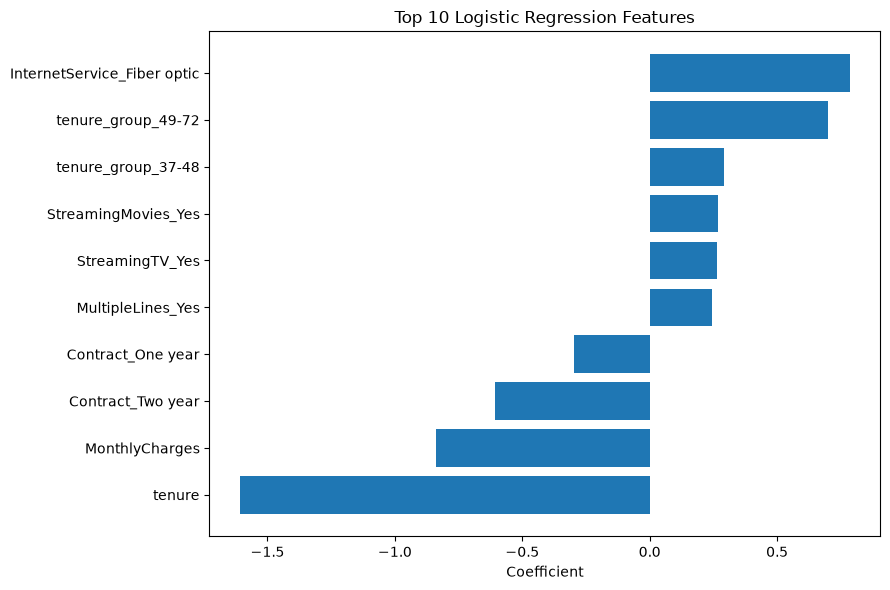


FILES SAVED SUCCESSFULLY
1. best_churn_model.pkl
2. churn_scaler.pkl
3. churn_features.pkl

FINAL PROJECT SUMMARY
Dataset Records       : 7043
Number of Features    : 34
Best Model            : Logistic Regression
Best Accuracy         : 80.27%

Customer Churn Prediction Project Completed Successfully! ✅


In [74]:
# ============================================================
# CUSTOMER CHURN PREDICTION - FINAL COMPLETE PIPELINE
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from xgboost import XGBClassifier


# ============================================================
# 1. PREPARE DATA
# ============================================================

# Remove leakage / unnecessary columns if they exist
columns_to_drop = []

if "customerID" in df.columns:
    columns_to_drop.append("customerID")

if "Churn_encoded" in df.columns:
    columns_to_drop.append("Churn_encoded")

df_model = df.drop(columns=columns_to_drop, errors="ignore").copy()

# Target
target = "Churn_Yes"

if target not in df_model.columns:
    raise ValueError("Churn_Yes column not found in dataframe.")

# Features and target
X = df_model.drop(target, axis=1)
y = df_model[target].astype(int)

print("=" * 60)
print("CUSTOMER CHURN PREDICTION - FINAL PIPELINE")
print("=" * 60)

print("\nDataset Shape:", df_model.shape)
print("Features:", X.shape[1])
print("Target:", target)


# ============================================================
# 2. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTrain Shape:", X_train.shape)
print("Test Shape :", X_test.shape)


# ============================================================
# 3. FEATURE SCALING
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ============================================================
# 4. LOGISTIC REGRESSION
# ============================================================

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

logistic_pred = logistic_model.predict(X_test_scaled)

logistic_accuracy = accuracy_score(
    y_test,
    logistic_pred
)


# ============================================================
# 5. RANDOM FOREST
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)


# ============================================================
# 6. XGBOOST
# ============================================================

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)

xgb_accuracy = accuracy_score(
    y_test,
    xgb_pred
)


# ============================================================
# 7. MODEL COMPARISON
# ============================================================

model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        logistic_accuracy,
        rf_accuracy,
        xgb_accuracy
    ]
})

model_results = model_results.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

print(model_results)

# Plot model comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_results,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.ylim(0, 1)

for i, value in enumerate(model_results["Accuracy"]):
    plt.text(
        i,
        value + 0.01,
        f"{value:.2%}",
        ha="center"
    )

plt.tight_layout()
plt.show()


# ============================================================
# 8. BEST MODEL
# ============================================================

best_model_name = model_results.iloc[0]["Model"]

if best_model_name == "Logistic Regression":
    best_model = logistic_model
    best_prediction = logistic_pred
elif best_model_name == "Random Forest":
    best_model = rf_model
    best_prediction = rf_pred
else:
    best_model = xgb_model
    best_prediction = xgb_pred

print("\nBest Model:", best_model_name)
print(
    "Best Accuracy:",
    f"{model_results.iloc[0]['Accuracy']:.2%}"
)


# ============================================================
# 9. BEST MODEL CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 60)
print("BEST MODEL - CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        best_prediction
    )
)


# ============================================================
# 10. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    best_prediction
)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title(f"{best_model_name} - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()


# ============================================================
# 11. LOGISTIC REGRESSION FEATURE COEFFICIENTS
# ============================================================

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.coef_[0]
})

feature_importance["Absolute_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

print("\n" + "=" * 60)
print("TOP 10 LOGISTIC REGRESSION FEATURES")
print("=" * 60)

print(
    feature_importance.head(10)[
        ["Feature", "Coefficient"]
    ]
)


# ============================================================
# 12. FEATURE IMPORTANCE VISUALIZATION
# ============================================================

top_features = feature_importance.head(10).sort_values(
    "Coefficient"
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.title("Top 10 Logistic Regression Features")
plt.xlabel("Coefficient")

plt.tight_layout()
plt.show()


# ============================================================
# 13. SAVE BEST MODEL + SCALER + FEATURES
# ============================================================

joblib.dump(
    best_model,
    "best_churn_model.pkl"
)

joblib.dump(
    scaler,
    "churn_scaler.pkl"
)

joblib.dump(
    list(X.columns),
    "churn_features.pkl"
)

print("\n" + "=" * 60)
print("FILES SAVED SUCCESSFULLY")
print("=" * 60)

print("1. best_churn_model.pkl")
print("2. churn_scaler.pkl")
print("3. churn_features.pkl")


# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("FINAL PROJECT SUMMARY")
print("=" * 60)

print(f"Dataset Records       : {len(df_model)}")
print(f"Number of Features    : {X.shape[1]}")
print(f"Best Model            : {best_model_name}")
print(
    f"Best Accuracy         : "
    f"{model_results.iloc[0]['Accuracy']:.2%}"
)

print("\nCustomer Churn Prediction Project Completed Successfully! ✅")